#### 1. Simulation behind Figure 3
Figure 3 simluates forward-in-time the dynamics of the four-locus system described in Fig 2: locus i and j on one chromosome, h and k on another. Their yield four unlinked pairs: ih, ik, jh, jk. There are also two linked pairs: ij and hk. The four unlinked pairs contribute to the point LD and $N_e$ estimate (Eqn 1), but they are correlated. For example, a large $cor(r^2_{ih}, r^2_{ik})$ will reduce the amount of information the system carry towards $N_e$. With four unlinked pairs there are six correlation terms. 

At the beginning of each simulation, the loci on the same chromosome are perfectly linked. Drift and recombination breaks down LD (along the same chromosome) gradually over time, whereas the LD between unlinked pairs quickly reach a stationary value (Waples, 2006). Note that this is an individual-based simulation, that each offspring is formed by randomly pairing of two parents. For each simulation, the six $r^2$ are recorded over time (as a block of numbers, a matrix). The whole system is further repeated for 5000 times independently. 

How do I read Figure 3? First, focus on the circles. From our repeated simulation we have 5000 pairs of $r^2_{ih}$ and $r^2_{ik})$. We can calculate the Pearson correlation between them per time point. These are the circles. Correlation starts high because loci h and k are initially linked. Then we overlay these circles with the average $r^2_{hk}$ sans sampling error, and this is the black dotted line. The two overlap each other perfectly. 

The diamonds and crosses are for different pairs. Note that the crosses belond to the correlation induced by a "disjoint pair" involving four distinct loci, which is weaker. This plot confirms Eqn 3-4 in the main text. And this is also a direct result of the Random Probe LD estimator (see preprint by Hui and Burt). 

In short, correlation among unlinked $r^2$ is quantified by the $r^2$ along the same chromosome. Now these correlations known and are fed into $\rho$. 

In [1]:
dyn.load('../cpp/linked_unlinked_ld.dll')

In [2]:
# THIS IS ONE SIM, RETURN 6 r2 OVER TIME AS A MATRTIX
f<-function(N=500, s=50, c1=0.01, c2=0.5, t=10)
{
    # OUTPUT r2
    r2<-matrix(nc=t+1, nr=6)
    # INITIALISE
    y<-.Call('initialise1', as.integer(N))
    # SAMPLING
    sam<-.Call('sample_unphase', y, as.integer(s))
    # CALCULATE r2, BURROWS
    r2[,1]<-.Call('cal_r2_burrows', sam)
    # FORWARD
    for (i in 1:t)
    {
        y<-.Call('forward', y, as.integer(N), as.numeric(c1), as.numeric(c2))
        sam<-.Call('sample_unphase', y, as.integer(s))
        r2[,i+1]<-.Call('cal_r2_burrows', sam)
    }
    return(r2)
}

In [3]:
# A FUNCTION TO CALCULATE CORRELATIONS BETWEEN PAIRS OF r2
f1<-function(x)
{
    cor_ihik<-rep(NA, ncol(x[[1]]))
    cor_ihjh<-cor_ihik
    cor_ihjk<-cor_ihik
    cor_ikjh<-cor_ihik
    cor_ikjk<-cor_ihik
    cor_jhjk<-cor_ihik
    
    for (i in 1:ncol(x[[1]]))
    {
        cor_ihik[i]<-cor(x[[2]][,i], x[[3]][,i], use='pairwise.complete.obs')
        cor_ihjh[i]<-cor(x[[2]][,i], x[[4]][,i], use='pairwise.complete.obs')
        cor_ihjk[i]<-cor(x[[2]][,i], x[[5]][,i], use='pairwise.complete.obs')
        cor_ikjh[i]<-cor(x[[3]][,i], x[[4]][,i], use='pairwise.complete.obs')
        cor_ikjk[i]<-cor(x[[3]][,i], x[[5]][,i], use='pairwise.complete.obs')
        cor_jhjk[i]<-cor(x[[4]][,i], x[[5]][,i], use='pairwise.complete.obs')
    }
    return(list(cor_ihik=cor_ihik, cor_ihjh=cor_ihjh, cor_ihjk=cor_ihjk, cor_ikjh=cor_ikjh, cor_ikjk=cor_ikjk, cor_jhjk=cor_jhjk))
}

In [4]:
# TO GENERATE FIG 3 WITH 5000 REPEATED SIMS
# PARAMETERS (NUMBER OF INDEP SIMS AND GENERATIONS)
times<-5000
t<-100
# POPULATION PARAMETERS (Ne, SAMPLE SIZE, TWO RECOM RATES)
N<-1000
s<-200
c1<-0.01
c2<-0.02
# EMPTY LIST / MATRICES TO STORE OUTPUTS
output<-list()
output[[1]]<-matrix(nc=t+1, nr=times)
output[[2]]<-output[[1]]
output[[3]]<-output[[1]]
output[[4]]<-output[[1]]
output[[5]]<-output[[1]]
output[[6]]<-output[[1]]
#
for (i in 1:times)
{
    temp<-f(N=N, s=s, t=t, c1=c1, c2=c2)
    output[[1]][i,]<-temp[1,] # ij
    output[[2]][i,]<-temp[2,] # ih
    output[[3]][i,]<-temp[3,] # ik
    output[[4]][i,]<-temp[4,] # jh
    output[[5]][i,]<-temp[5,] # jk
    output[[6]][i,]<-temp[6,] # hk
}
invisible(gc())
# CALCULATE CORRELATION BETWEEN r^2
temp<-f1(output)
# WE JUST EXPORT THREE OF THE SIX CORRELATIONS
cor_ihik<-temp$cor_ihik
cor_ihjh<-temp$cor_ihjh
cor_ihjk<-temp$cor_ihjk

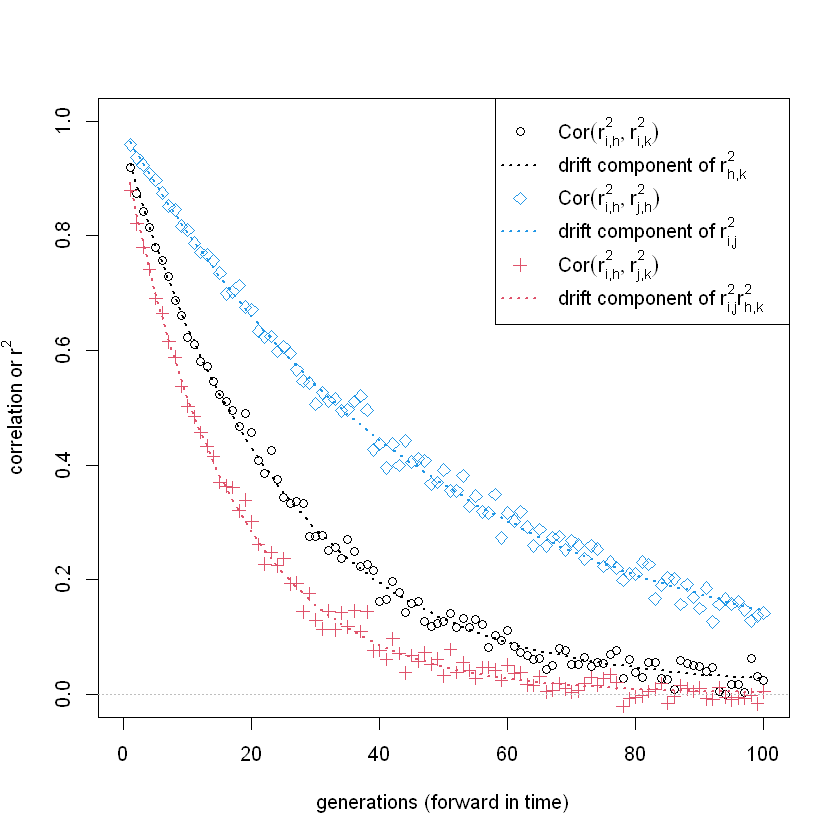

In [5]:
# PLOT EVERYTHING OUT
plot(0:t, cor_ihik, col=1, pch=1, 
     type='p', ylim=c(0, 1), xlim=c(0, 100), 
     xlab='generations (forward in time)', ylab=expression(correlation~or~r^2))
points(0:t, cor_ihjk, col=2, pch=3)
points(0:t, cor_ihjh, col=4, pch=5)
lines(0:t, apply(output[[1]], 2, mean, na.rm=T)-1/s-3.19/s^2, col=4, lty=3, lwd=2)
lines(0:t, apply(output[[6]], 2, mean, na.rm=T)-1/s-3.19/s^2, col=1, lty=3, lwd=2)
lines(0:t, (apply(output[[1]], 2, mean, na.rm=T)-1/s-3.19/s^2)*(apply(output[[6]], 2, mean, na.rm=T)-1/s-3.19/s^2), col=2, lty=3, lwd=2)
abline(h=0, col='grey', lty=3)
legend('topright', legend=c(expression(Cor(r['i,h']^2, r['i,k']^2)), expression(drift~component~of~r['h,k']^2), 
                            expression(Cor(r['i,h']^2, r['j,h']^2)), expression(drift~component~of~r['i,j']^2), 
                            expression(Cor(r['i,h']^2, r['j,k']^2)), expression(drift~component~of~r['i,j']^2*r['h,k']^2)), 
       col=c(1,1,4,4,2,2), pch=c(1,NA,5,NA,3,NA), lty=rep(c(NA,3), 2), lwd=rep(c(NA,2), 2))

#### 2. Figure S1
Figure S1 is produced from the same set of simulations. It shows the average $r^2$ over time which is probably quite easy to follow. With six $r^2$ we have six plots: four unlinked (top two rows), two linked (bottomw row). 

The four unlinked $r^2$ share the same equilibrium value following Waples' empirical formula. They should in theory begins with $r^2=0$ (or a very small value) at the 0th generation, but are not shown here. They quickly move to their equilibrium value due to large recombination (c=0.5 for unlinked). 

The two linked cases are typical LD decays over time, with rates governed by their c (Hill and Robertson, 1968). 

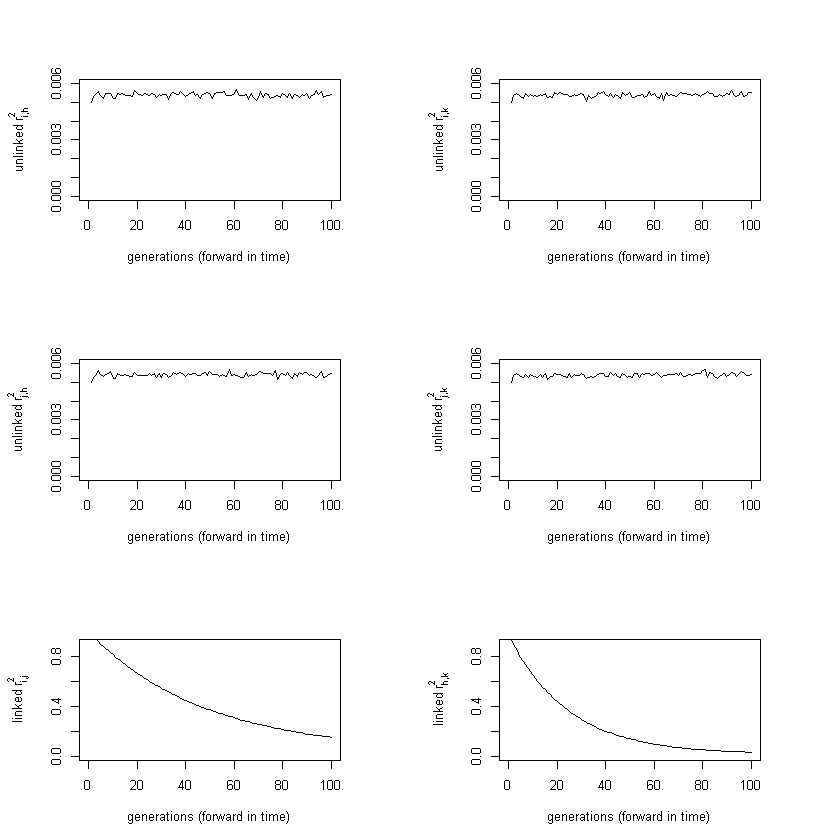

In [6]:
# EXTRA PLOTS FOR SI
par(mfrow=c(3,2), mar=c(5,5,5,5))
plot(0:t, apply(output[[2]], 2, mean, na.rm=T), type='l', ylim=c(0, 0.006), xlim=c(0, 100),
     xlab='generations (forward in time)', ylab=expression(unlinked~r['i,h']^2))
plot(0:t, apply(output[[3]], 2, mean, na.rm=T), type='l', ylim=c(0, 0.006), xlim=c(0, 100),
     xlab='generations (forward in time)', ylab=expression(unlinked~r['i,k']^2))
plot(0:t, apply(output[[4]], 2, mean, na.rm=T), type='l', ylim=c(0, 0.006), xlim=c(0, 100),
     xlab='generations (forward in time)', ylab=expression(unlinked~r['j,h']^2))
plot(0:t, apply(output[[5]], 2, mean, na.rm=T), type='l', ylim=c(0, 0.006), xlim=c(0, 100),
     xlab='generations (forward in time)', ylab=expression(unlinked~r['j,k']^2))
plot(0:t, apply(output[[1]], 2, mean, na.rm=T), type='l', ylim=c(0, 0.9), xlim=c(0, 100),
     xlab='generations (forward in time)', ylab=expression(linked~r['i,j']^2))
plot(0:t, apply(output[[6]], 2, mean, na.rm=T), type='l', ylim=c(0, 0.9), xlim=c(0, 100),
     xlab='generations (forward in time)', ylab=expression(linked~r['h,k']^2))

#### 3. Figure 4 on variance
The overall LD point estimate is the avearge of the four unlinked $r^2$ (Eqn 1). With 5000 indpendent repeats we have 5000 point estimates per time point. We can plot the variance over time. And this is the first plot below (not shown in the main text). At the beginning the unlinked $r^2$ are more correlated (as explained above), thus the $var(\hat{r^2})$ is higher. The next question is, how high is high?  

Then we move onto the next step. Classical theory says that $k\hat{r^2}/E[r^2]$ follows a chi-square distribution with df=k equals the numner of unlinked $r^2$, in this case, df=4. For chi-square df=4 the variance is 8. All these assumes independent $r^2$. 

As our unlinked $r^2$ are correlated (more correlated at the beginning of the simulation), the variance should be larger than that specified by chi-square. And Eqn 2 derives that we need to multiple the chi-square variance by $(1+2\rho)$. In other words: 

$$Var(4\hat{r^2}/E[r^2])=8(1+2\rho)$$

If we fling the 8 to the left hand side of the equation we have Figure 4 below. And to calculate $\rho$ we reuse our correlations (circles/crosses/diamonds) we found above, in the dotted line. 

[1] 5000  101

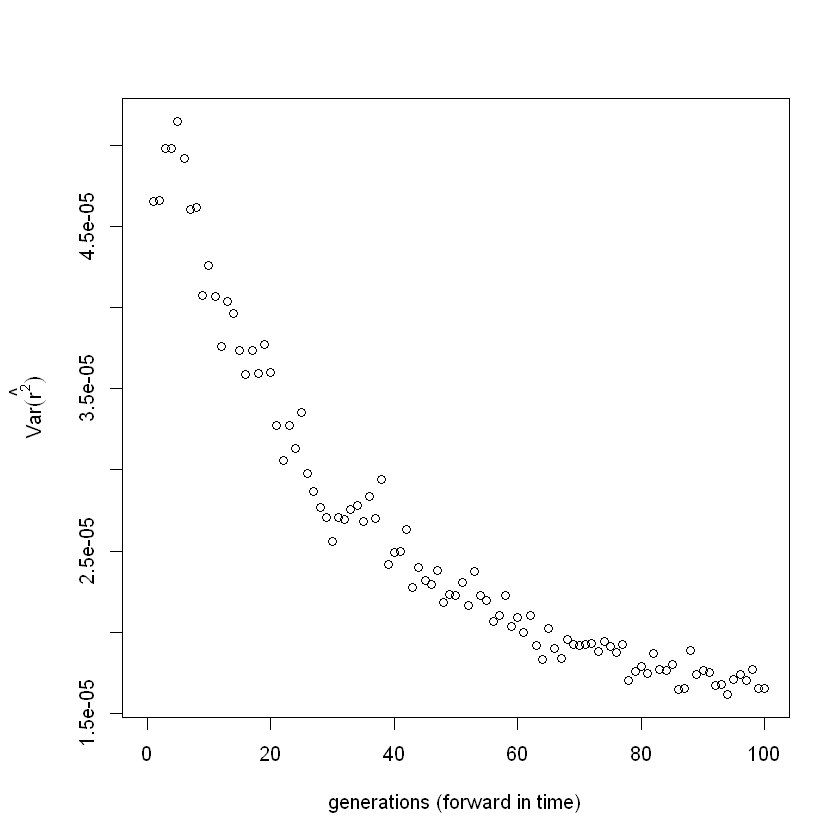

In [16]:
# POINT r^2 ESTIMATE, AVERAGE OF THE FOUR UNLINKED PAIRS
point_r2<-(output[[2]]+output[[3]]+output[[4]]+output[[5]])/4
dim(point_r2)
# CALCULATE VARIANCE PER TIME POINT, AND PLOT
var_r2<-apply(point_r2, 2, var, na.rm=T)
par(mar=c(5.1, 5.1, 4.1, 2.1))
plot(0:t, var_r2, xlab='generations (forward in time)', ylab=expression(Var(hat(r^2))))

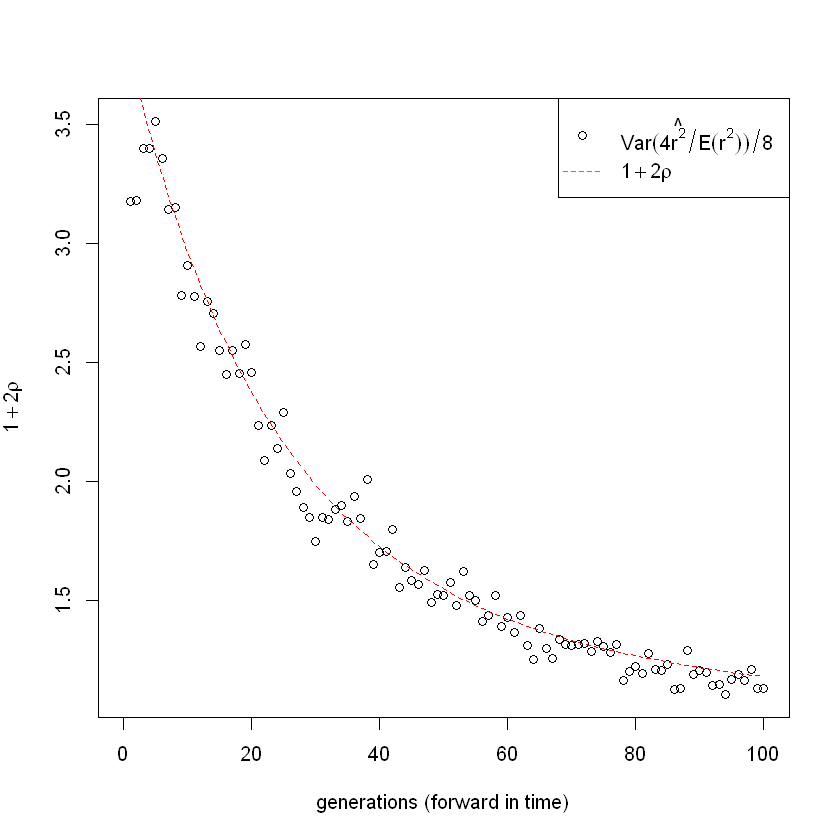

In [26]:
# TRUE r^2, WAPLES'
true_r2<-1/(3*N)-0.69/N^2+1/s+3.19/s^2

# CALCULATE VAR(4r^2/true_r2)
variance<-apply(point_r2, 2, function(x) {var(4*x/true_r2, na.rm=T)})
# ESTIMATE rho FROM CORRELATIONS
rho<-(output[[6]]-1/s-3.19/s^2)+(output[[1]]-1/s-3.19/s^2)+(output[[1]]-1/s-3.19/s^2)*(output[[6]]-1/s-3.19/s^2)
rho<-2*rho/4
rho<-apply(rho, 2, mean, na.rm=T)
# PLOT
plot(0:t, variance/8, xlim=c(0, 100), 
    xlab='generations (forward in time)', ylab=expression(1+2*rho))
lines(0:t, 1+2*rho, col='red', lty=2)
legend('topright', legend=c(expression(Var(4*hat(r^2)/E(r^2))/8), expression(1+2*rho)), col=1:2, pch=c(1,NA), lty=c(NA,2))
abline(h=1, col='grey', lty=2)